# 02 - Model walkthrough: shrinkage, composite score, out-of-time validation, archetypes, exposure
Reads `artifacts/` produced by `make train`. Sellers are supplier proxies.

In [1]:
import os, json, duckdb, pandas as pd, numpy as np, matplotlib.pyplot as plt
os.chdir('..') if os.path.basename(os.getcwd()) == 'notebooks' else None
pd.set_option('display.width', 160); pd.set_option('display.max_columns', 20)
con = duckdb.connect('data/processed/olist.duckdb', read_only=True)
from supplier_risk.shrinkage import BetaPrior, posterior_mean
t = json.load(open('artifacts/train_summary.json'))
sc = pd.read_parquet('artifacts/seller_scores.parquet')

## 1. Empirical-Bayes priors (maximum marginal likelihood)

In [2]:
pd.DataFrame(t['priors'], index=['a','b','mean','strength']).T

,a,b,mean,strength
late,2.029576,29.045970,0.065311,31.075546
handoff,0.506332,4.057094,0.110954,4.563426
cancel,0.111867,8.007102,0.013779,8.118970


In [3]:
p = BetaPrior(*t['priors']['late'][:2])
pd.DataFrame({'n_delivered':[1,5,20,100,1000], 'n_late':[1,2,4,20,200]}).assign(
    raw=lambda d: d.n_late/d.n_delivered, shrunk=lambda d: posterior_mean(d.n_late, d.n_delivered, p))

,n_delivered,n_late,raw,shrunk
0,1,1,1.0,0.094451
1,5,2,0.4,0.111698
2,20,4,0.2,0.118052
3,100,20,0.2,0.168068
4,1000,200,0.2,0.195941


A seller with 1 late out of 1 is pulled almost entirely to the prior; at 1,000 deliveries the data dominate.

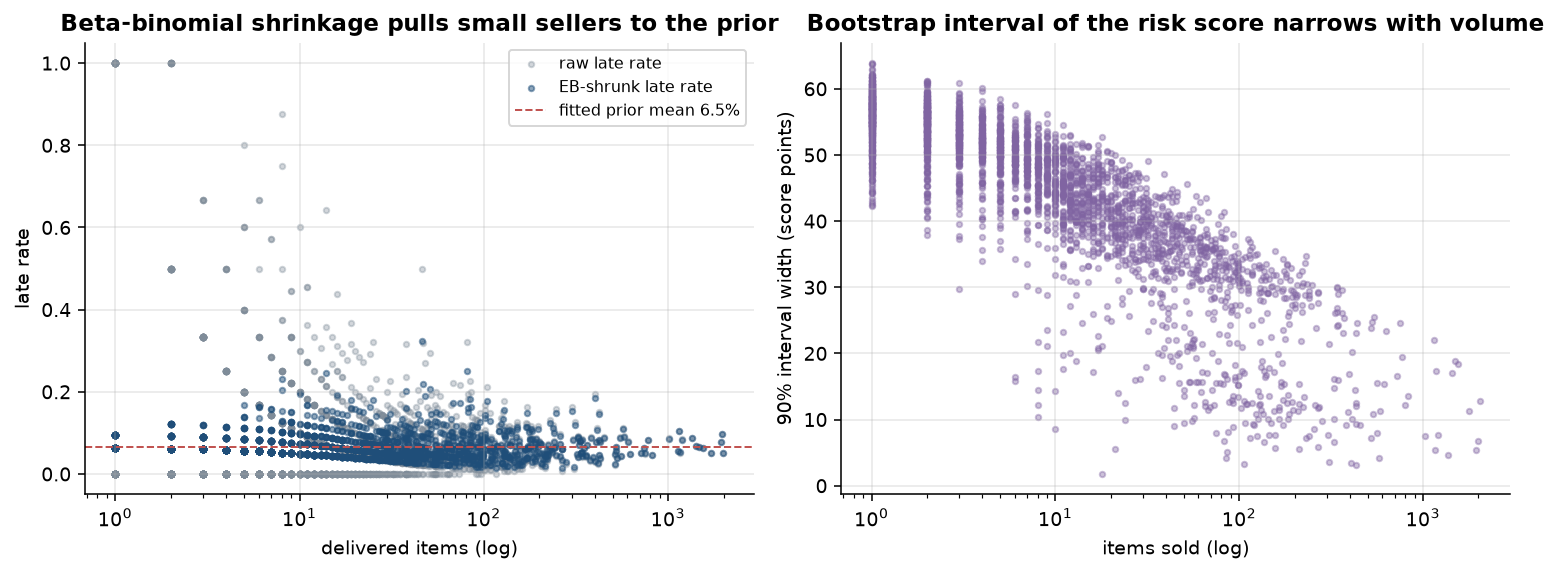

In [4]:
from IPython.display import Image; Image('docs/figures/shrinkage_and_intervals.png', width=850)

## 2. Composite score and tiers

In [5]:
pd.read_csv('artifacts/risk_tier_summary.csv')

,risk_tier,n_sellers,gmv,late_gmv,gmv_at_risk,n_items,n_late,n_delivered,exposure_ASSUMED,late_rate,gmv_share,late_gmv_share
0,Elevated,309,810360.98,107980.55,79478.600776,6991.0,802.0,6677.0,45275.645076,0.120114,0.059622,0.109522
1,High,310,877208.51,172047.16,106090.895510,7290.0,1145.0,6847.0,62516.481822,0.167227,0.064540,0.174503
2,Low,1547,9121629.51,434806.31,494317.318308,72973.0,3085.0,71819.0,459044.131616,0.042955,0.671120,0.441014
3,Moderate,929,2782444.70,271090.32,233773.028302,25396.0,2232.0,24846.0,162641.230727,0.089833,0.204717,0.274961


In [6]:
pd.read_csv('artifacts/top25_risk_sellers.csv').head(10)

,risk_rank,seller_id,seller_state,top_category,n_items,gmv,late_rate_raw,late_rate_shrunk,late_rate_lo90,late_rate_hi90,seller_handoff_late_rate,mean_review_score,risk_score,risk_score_lo90,risk_score_hi90,archetype,gmv_at_risk
0,1,ec2e006556300a79a5a91e4876ab3a56,SP,construction_tools_construction,8.0,125.20,0.500000,0.135657,0.056778,0.237028,0.615930,1.375000,95.573506,74.440065,96.153958,Unclustered (<20 items),16.984318
1,2,973f21788dfab357250f69a8dcb7ddee,MG,sports_leisure,21.0,909.00,0.368421,0.180319,0.099610,0.275651,0.742945,2.333333,95.009693,89.771971,95.341034,Cancellation-prone,163.910029
2,3,538caafddff204241cecbf3a02e6b3cf,SP,baby,9.0,148.30,0.375000,0.128714,0.053709,0.225446,0.517879,2.555556,94.860258,74.515024,95.616478,Unclustered (<20 items),19.088308
3,4,ec4608a1f76453166bb312b2968aeaf4,SP,furniture_decor,35.0,1181.75,0.137931,0.100367,0.045505,0.170381,0.462001,2.685714,92.323910,62.656300,94.617771,Cancellation-prone,118.608177
4,5,c1d1ebb4745cc43cb6f05e9c8a705c9a,SP,unknown,3.0,34.50,1.000000,0.094451,0.027339,0.190316,0.270756,2.333333,91.934572,54.859370,95.990549,Unclustered (<20 items),3.258568
5,6,6ee85be3693ed79a8e80718743d80655,SP,electronics,13.0,484.50,0.400000,0.111698,0.040414,0.207548,0.366640,1.923077,91.927302,62.990953,93.791357,Unclustered (<20 items),54.117805
6,7,e5bd51692380fd8cabb19b756b95e714,SP,unknown,3.0,119.70,1.000000,0.121829,0.044298,0.225497,0.381863,2.333333,91.849758,64.090953,93.848950,Unclustered (<20 items),14.582985
7,8,ad781527c93d00d89a11eecd9dcad7c1,SP,baby,44.0,6899.57,0.315789,0.203105,0.129189,0.286852,0.424814,3.068182,91.531502,83.142407,92.197981,Slow dispatchers,1401.335849
8,9,8d92f3ea807b89465643c219455e7369,SP,unknown,8.0,121.20,0.875000,0.231080,0.129833,0.348148,0.677071,1.000000,91.511309,86.144184,96.486914,Unclustered (<20 items),28.006891
9,10,b19f3ca2ea475913750f25a5c37c8d8f,MG,housewares,24.0,6202.91,0.315789,0.160349,0.084234,0.251988,0.488313,2.791667,90.085622,80.664136,90.532633,Slow dispatchers,994.631887


In [7]:
pd.read_csv('artifacts/weight_sensitivity_ranking.csv')

,weights,spearman_vs_base,top100_overlap
0,late_heavy,0.979108,0.88
1,handoff_heavy,0.969659,0.86
2,balanced_alt,0.991566,0.81


## 3. Out-of-time validation vs baselines

In [8]:
ev = pd.read_csv('artifacts/oot_metrics_main.csv'); ev.round(3)

,target,score,item_auc,seller_auc,spearman,lift_top10,capture_top10,late_rate_top10,base_late_rate
0,End-to-end late delivery,Composite risk score (shrunk),0.536,0.597,0.141,1.212,0.131,0.095,0.078
1,End-to-end late delivery,Shrunk late rate (EB) only,0.543,0.612,0.185,1.187,0.138,0.093,0.078
2,End-to-end late delivery,Shrunk hand-off late rate (EB) only,0.522,0.568,0.087,1.057,0.093,0.083,0.078
3,End-to-end late delivery,Baseline: raw late rate,0.539,0.602,0.221,1.222,0.063,0.096,0.078
4,End-to-end late delivery,Baseline: raw hand-off late rate,0.519,0.568,0.123,1.245,0.071,0.098,0.078
5,End-to-end late delivery,Baseline: volume only (smaller = riskier),0.497,0.465,-0.128,1.010,0.034,0.079,0.078
6,End-to-end late delivery,Sensitivity: late_heavy weights,0.540,0.605,0.162,1.236,0.138,0.097,0.078
7,End-to-end late delivery,Sensitivity: handoff_heavy weights,0.532,0.591,0.127,1.185,0.139,0.093,0.078
8,End-to-end late delivery,Sensitivity: balanced_alt weights,0.535,0.591,0.127,1.350,0.104,0.106,0.078
9,Seller hand-off late,Composite risk score (shrunk),0.666,0.701,0.344,2.365,0.256,0.210,0.089


In [9]:
pd.DataFrame(t['auc_deltas']).T.round(4)

,delta,lo95,hi95,p_le_0
composite_vs_raw_late_late,-0.0024,-0.0135,0.0097,0.605
eb_handoff_vs_raw_handoff_late,0.0029,-0.0032,0.0128,0.225
composite_vs_volume_late,0.0388,0.0130,0.0626,0.005
composite_vs_raw_late_handoff,0.0843,0.0569,0.1148,0.000
eb_handoff_vs_raw_handoff_handoff,0.0230,0.0120,0.0388,0.000
composite_vs_volume_handoff,0.1454,0.0802,0.2320,0.000


In [10]:
pd.read_csv('artifacts/oot_backtest_metrics.csv').query("score in ['Composite risk score (shrunk)','Shrunk hand-off late rate (EB) only','Baseline: raw hand-off late rate']")[['split','target','score','item_auc','lift_top10']].round(3)

,split,target,score,item_auc,lift_top10
0,2017-07-01->2018-01-01,End-to-end late delivery,Composite risk score (shrunk),0.545,1.127
2,2017-07-01->2018-01-01,End-to-end late delivery,Shrunk hand-off late rate (EB) only,0.564,1.564
4,2017-07-01->2018-01-01,End-to-end late delivery,Baseline: raw hand-off late rate,0.571,1.586
9,2017-07-01->2018-01-01,Seller hand-off late,Composite risk score (shrunk),0.584,1.888
11,2017-07-01->2018-01-01,Seller hand-off late,Shrunk hand-off late rate (EB) only,0.648,3.280
13,2017-07-01->2018-01-01,Seller hand-off late,Baseline: raw hand-off late rate,0.635,3.491
18,2017-10-01->2018-04-01,End-to-end late delivery,Composite risk score (shrunk),0.536,1.089
20,2017-10-01->2018-04-01,End-to-end late delivery,Shrunk hand-off late rate (EB) only,0.541,1.296
22,2017-10-01->2018-04-01,End-to-end late delivery,Baseline: raw hand-off late rate,0.540,1.297
27,2017-10-01->2018-04-01,Seller hand-off late,Composite risk score (shrunk),0.605,1.769


In [11]:
pd.read_csv('artifacts/oot_shrinkage_calibration.csv').round(4)

,vol_band,n_sellers,next_items,mae_raw,mae_shrunk
0,<5,327,4462.0,0.1244,0.0580
1,5-19,356,7558.0,0.0671,0.0517
2,20-99,302,12995.0,0.0581,0.0528
3,100+,96,20374.0,0.0409,0.0396


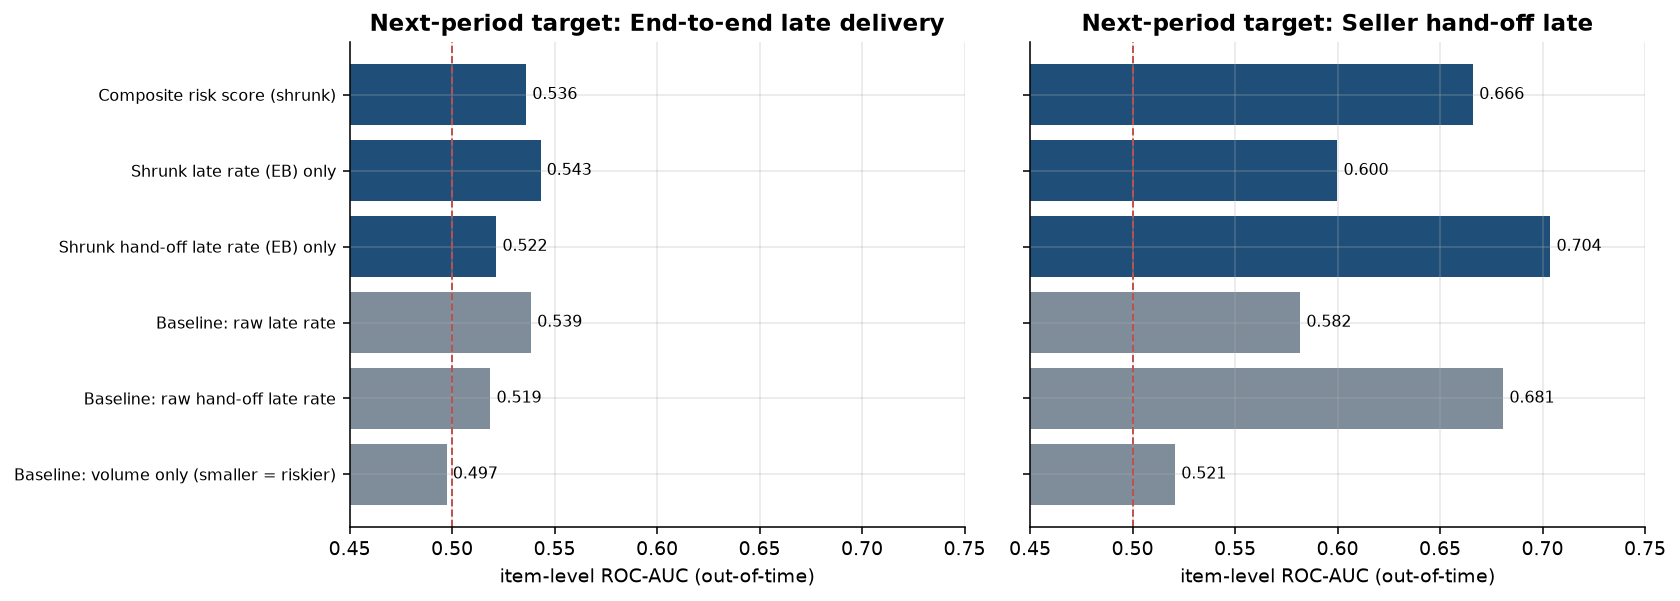

In [12]:
Image('docs/figures/oot_validation_auc.png', width=900)

**Reading:** seller scores predict next-period *hand-off* lateness (seller-controlled) far better than *end-to-end* lateness, which is dominated by lane/carrier/calendar effects (see R GLMM ICC).

## 4. Archetypes

In [13]:
pd.read_csv('artifacts/cluster_selection.csv').round(3)

,k,silhouette,inertia,gmm_bic
0,3,0.169,4321.470,13088.412
1,4,0.174,3892.457,12622.144
2,5,0.154,3549.547,12518.332
3,6,0.159,3267.385,11706.756
4,7,0.168,3060.962,11877.243


In [14]:
pd.read_csv('artifacts/archetype_profiles.csv').round(3)

,archetype,n_sellers,gmv,median_items,late_rate_shrunk,handoff_late,review,freight_to_price,cancel_rate,median_delivery_days,risk_score,gmv_at_risk,gmv_share
0,Slow dispatchers,144,1425948.13,50.5,0.100,0.258,3.732,0.220,0.003,13.376,70.424,150693.671,0.105
1,Cancellation-prone,34,219615.25,29.0,0.070,0.117,3.704,0.188,0.038,11.558,62.773,17667.342,0.016
2,High-volume core suppliers,420,8756350.55,72.0,0.053,0.048,4.171,0.151,0.002,9.861,34.422,541737.623,0.644
3,Small occasional sellers,296,943945.31,39.0,0.048,0.036,4.213,0.316,0.003,8.323,33.011,49862.665,0.069


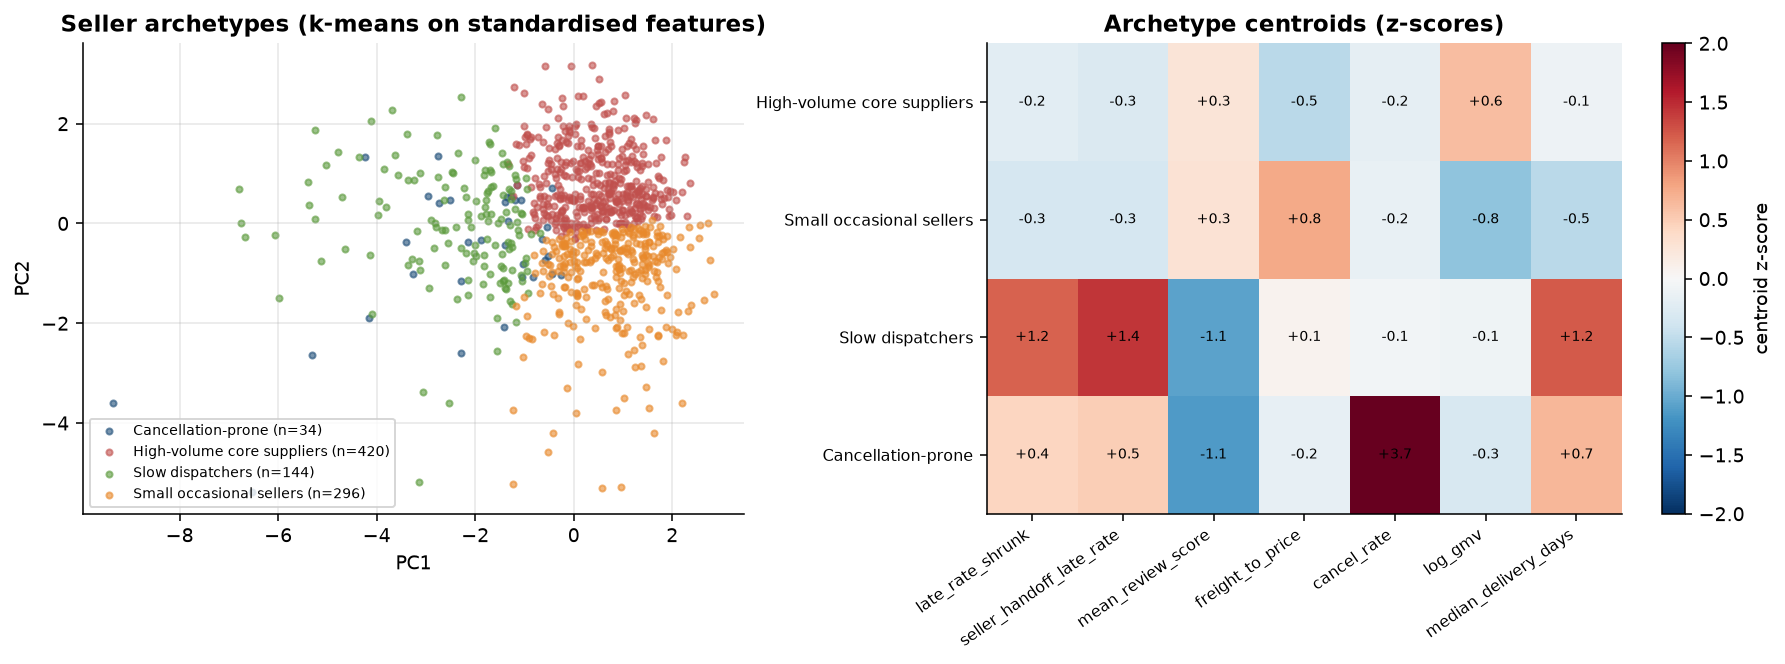

In [15]:
Image('docs/figures/seller_archetypes.png', width=900)

## 5. Exposure and scenario (ASSUMED parameters)

In [16]:
{k: round(v) if v > 10 else round(v, 3) for k, v in t['exposure_totals'].items()}

{'gmv': 13591644,
 'late_gmv': 985924,
 'gmv_at_risk': 913660,
 'freight': 2251910,
 'wc_in_transit': 407176,
 'wc_excess_delay': 29782,
 'total_exposure_ASSUMED': 729477,
 'top10pct_gmv_at_risk_share': 0.71,
 'top10pct_gmv_share': 0.675}

In [17]:
pd.DataFrame([t['scenario_base_ASSUMED'], t['scenario_raw_baseline_ASSUMED']], index=['composite','raw late rate']).T

,composite,raw late rate
top_share,0.100000,0.100000
realloc_frac,0.500000,0.500000
improvement_ASSUMED,0.500000,0.500000
n_top_sellers,108.000000,108.000000
top_gmv_share,0.099961,0.050670
top_late_rate_gmv,0.095003,0.099066
rest_late_rate_gmv,0.085078,0.085376
moved_gmv,258282.385000,130922.055000
late_gmv_before,444779.780000,444779.780000
late_gmv_avoided,1281.798951,896.146342


In [18]:
pd.read_csv('artifacts/exposure_sensitivity.csv').round(3)

,late_cost_pct_of_gmv,freight_absorb_pct,total_exposure_ASSUMED,top_decile_risk_exposure_ASSUMED,top_decile_share
0,0.02,0.1,251685.786,22159.089,0.088
1,0.02,0.3,702067.694,59333.755,0.085
2,0.02,0.5,1152449.602,96508.421,0.084
3,0.05,0.1,279095.581,25341.816,0.091
4,0.05,0.3,729477.489,62516.482,0.086
5,0.05,0.5,1179859.397,99691.148,0.084
6,0.10,0.1,324778.573,30646.361,0.094
7,0.10,0.3,775160.481,67821.027,0.087
8,0.10,0.5,1225542.389,104995.693,0.086


## 6. R layer summary

In [19]:
json.load(open('artifacts/r_glm/r_summary.json'))

{'n_orders': 96470,
 'late_rate': 0.0677309,
 'glm_auc': 0.77063154,
 'glm_auc_without_handoff': 0.71704406,
 'lrt_handoff_dev': 2092.73897783,
 'lrt_handoff_p': 0,
 'or_handoff': 4.9521,
 'or_handoff_lo': 4.6464,
 'or_handoff_hi': 5.2765,
 'or_same_state': 0.48464,
 'hosmer_lemeshow_stat': 152.34651827,
 'hosmer_lemeshow_p': 6.35102407e-29,
 'max_gvif_adj': 1.67208115,
 'glmm_n_orders': 94081,
 'glmm_n_sellers': 1754,
 'glmm_seller_sd': 0.45061729,
 'glmm_icc': 0.05813351,
 'glmm_seller_sd_without_handoff': 0.56296554,
 'glmm_icc_without_handoff': 0.08787023,
 'nb_theta': 5.47769184,
 'poisson_dispersion': 4.60913712,
 'irr_handoff': 1.6464,
 'irr_same_state': 0.59518,
 'kruskal_category_H': 751.73758653,
 'kruskal_category_p': 1.23943184e-149,
 'r_version': 'R version 4.5.0 (2025-04-11)',
 'pkg_versions': {'MASS': '7.3.65',
  'lme4': '1.1.37',
  'ggplot2': '3.5.1',
  'dplyr': '1.1.4',
  'broom': '1.0.7',
  'pROC': '1.18.5',
  'car': '3.1.3'}}